# DML Validation Audit — 5 November 2026

**Purpose:** Audit the cross-fitting design, treatment overlap, and interpretation of the exploratory DML notebook.

**Dataset:** `project1_algorithmic_pricing_synthetic_dataset.csv`

This notebook is a diagnostic audit, not a new causal estimator. It deliberately does not claim a validated ATE or CATE.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

DATA_CANDIDATES = [
    Path("project1_algorithmic_pricing_synthetic_dataset.csv"),
    Path("../project1_algorithmic_pricing_synthetic_dataset.csv"),
    Path("/mnt/data/project1_algorithmic_pricing_synthetic_dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place the project CSV beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values(["date", "region"]).reset_index(drop=True)
TREATMENT_DATE = pd.Timestamp("2025-05-01")
dates = np.array(sorted(df["date"].unique()))
print("Shape:", df.shape)
print("Unique dates:", len(dates))
print("Treated rows:", int(df.treatment.sum()))
print("Treated regions:", sorted(df.loc[df.treatment.eq(1), "region"].unique()))
print("Treatment rule matches North × post:", bool((df.treatment == ((df.region.eq("North")) & (df.date.ge(TREATMENT_DATE))).astype(int)).all()))

Shape: (540, 11)
Unique dates: 180
Treated rows: 60
Treated regions: ['North']
Treatment rule matches North × post: True


## 1. Audit the existing grouped cross-fitting

The current DML notebook uses `GroupKFold(n_splits=5)` with date as the group. This correctly keeps the three regional rows from one date together. However, GroupKFold is **not chronological**: each test fold contains dates spread across the full January–June period, while the training set contains later dates than most test dates.

That is a concern when treatment is introduced at a fixed date and the dataset has time trends. A nuisance model can learn from future treatment periods while predicting earlier dates.

In [2]:
gkf = GroupKFold(n_splits=5)
group_rows = []
for fold, (train_idx, test_idx) in enumerate(gkf.split(df, df["treatment"], groups=df["date"]), start=1):
    train_dates = np.sort(df.loc[train_idx, "date"].unique())
    test_dates = np.sort(df.loc[test_idx, "date"].unique())
    future_test_dates = sum(pd.Timestamp(train_dates.max()) > pd.Timestamp(d) for d in test_dates)
    group_rows.append({
        "Fold": fold,
        "Test date range": f"{pd.Timestamp(test_dates.min()).date()} to {pd.Timestamp(test_dates.max()).date()}",
        "Train dates": len(train_dates),
        "Test dates": len(test_dates),
        "Treated rows in train": int(df.loc[train_idx, "treatment"].sum()),
        "Treated rows in test": int(df.loc[test_idx, "treatment"].sum()),
        "Test dates with later dates in training": int(future_test_dates),
    })
groupkfold_audit = pd.DataFrame(group_rows)
display(groupkfold_audit)
print("Finding: grouped folds avoid same-date row leakage, but they do not prevent future-to-past leakage.")

,Fold,Test date range,Train dates,Test dates,Treated rows in train,Treated rows in test,Test dates with later dates in training
0,1,2025-01-05 to 2025-06-29,144,36,48,12,35
1,2,2025-01-04 to 2025-06-28,144,36,48,12,36
2,3,2025-01-03 to 2025-06-27,144,36,48,12,36
3,4,2025-01-02 to 2025-06-26,144,36,48,12,36
4,5,2025-01-01 to 2025-06-25,144,36,48,12,36


Finding: grouped folds avoid same-date row leakage, but they do not prevent future-to-past leakage.


## 2. Check whether chronological cross-fitting is feasible

A forward-chaining split trains only on dates before the test block. Here, all observations before 1 May 2025 are untreated. Therefore, early training windows contain only treatment class 0, so a propensity classifier cannot learn both classes. Even after treatment begins, only North is treated.

This is not a software bug. It is a design limitation in the available treatment assignment.

In [3]:
tscv = TimeSeriesSplit(n_splits=5)
time_rows = []
for fold, (train_date_idx, test_date_idx) in enumerate(tscv.split(dates), start=1):
    train_dates = dates[train_date_idx]
    test_dates = dates[test_date_idx]
    train = df[df.date.isin(train_dates)]
    test = df[df.date.isin(test_dates)]
    time_rows.append({
        "Fold": fold,
        "Train end": pd.Timestamp(train_dates.max()).date(),
        "Test start": pd.Timestamp(test_dates.min()).date(),
        "Train rows": len(train),
        "Test rows": len(test),
        "Treated rows in train": int(train.treatment.sum()),
        "Treated rows in test": int(test.treatment.sum()),
        "Both treatment classes in training": train.treatment.nunique() == 2,
    })
time_audit = pd.DataFrame(time_rows)
display(time_audit)
print("Forward-chaining folds with both treatment classes in training:",
      int(time_audit["Both treatment classes in training"].sum()), "of", len(time_audit))

,Fold,Train end,Test start,Train rows,Test rows,Treated rows in train,Treated rows in test,Both treatment classes in training
0,1,2025-01-30,2025-01-31,90,90,0,0,False
1,2,2025-03-01,2025-03-02,180,90,0,0,False
2,3,2025-03-31,2025-04-01,270,90,0,0,False
3,4,2025-04-30,2025-05-01,360,90,0,30,False
4,5,2025-05-30,2025-05-31,450,90,30,30,True


Forward-chaining folds with both treatment classes in training: 1 of 5


## 3. Visualise treatment assignment and structural overlap

Treatment is exactly North × post-1-May. This means the treatment indicator is determined by region and time rather than varying across comparable markets. A high propensity AUC is therefore a warning of separation, not evidence of a good causal model.

period,Post,Pre
region,,
North,1.0,0.0
South,0.0,0.0
West,0.0,0.0


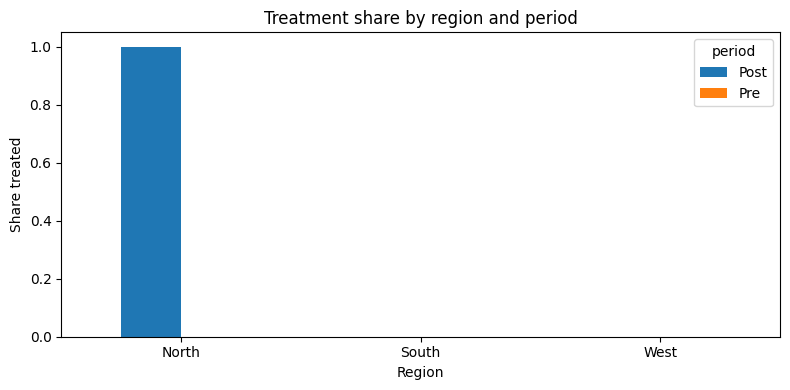

Treated regions: 1
Untreated regions: 3
Unique treated market units: one region (North)


In [4]:
df["period"] = np.where(df.date < TREATMENT_DATE, "Pre", "Post")
treat_share = df.pivot_table(index="region", columns="period", values="treatment", aggfunc="mean")
display(treat_share)
ax = treat_share.plot(kind="bar", figsize=(8, 4), ylim=(0, 1.05))
ax.set_title("Treatment share by region and period")
ax.set_ylabel("Share treated")
ax.set_xlabel("Region")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Treated regions:", df.loc[df.treatment.eq(1), "region"].nunique())
print("Untreated regions:", df.loc[df.treatment.eq(0), "region"].nunique())
print("Unique treated market units: one region (North)")

## 4. Review of propensity overlap results from the exploratory DML notebook

The previously executed exploratory notebook reported the following cross-fitted propensity ranges:

| Nuisance specification | Treated range | Untreated range | Common support |
|---|---:|---:|---|
| Ridge + logistic | 0.2959–0.7870 | 0.0009–0.2790 | None |
| Random forest | 0.4898–1.0000 | 0.0000–0.0887 | None |

The intervals do not intersect. Clipping propensity predictions for numerical stability does not create genuine overlap. The reported DML coefficients (875.48 and 10,001.95 revenue units) are highly specification-sensitive and must remain exploratory diagnostics, not causal ATE estimates.

## 5. Covariate timing and model-sensitivity cautions

- `our_price` is the intervention mechanism and should not be casually controlled for when estimating the total effect of a price change.
- `units_sold` may be downstream of price and may be a mediator.
- `marketing_spend` and `promotion_active` are only valid adjustment variables if the data-generation process confirms they were determined before treatment and were not affected by the intervention.
- `competitor_price` may be a confounder, but its timing and causal relationship should also be confirmed.
- Region and calendar variables explain treatment assignment; including them exposes the lack of overlap rather than fixing it.

Cross-fitting controls overfitting in nuisance estimation under appropriate conditions. It cannot repair deterministic treatment assignment, missing common support, unmeasured region-specific shocks, or a lack of independently treated markets.

## 6. Validation conclusion and recommended next steps

**Conclusion:** The current DML notebook is a useful exploratory implementation, but its cross-fitting is not time-respecting and the data do not support a defensible causal ATE/CATE.

1. Keep the existing GroupKFold results labelled exploratory; disclose that folds train on future dates for many test observations.
2. Do not replace them with forward-chaining DML estimates: early training folds contain no treated examples, so the propensity model is not estimable.
3. Request data-generation documentation to establish whether marketing spend and promotion status are pre-treatment covariates.
4. Request additional data with multiple treated and untreated markets and treatment variation within comparable market-time profiles.
5. Until then, use Synthetic Control as the primary descriptive counterfactual analysis and report its donor sensitivity and limitations. Do not claim that DML independently confirms the Synthetic Control estimate.

**No validated causal ATE or CATE is reported by this audit.**